# 16 · Graph topology and E/I neuronal dynamics
## Goal
Move from spatial coupling to explicit graph families using the validated FHN graded-synapse equations. Compare fixed-size graphs under a common recipient coefficient budget, then test whether aligning E/I labels with graph partitions changes bipartite-network behavior.

This is an exploratory, reproducible model experiment. Run top-to-bottom with Python, NumPy, SciPy, pandas, Matplotlib and NetworkX. All files are written to `results/fhn_ei_graph_topology/`; notebooks 1–15 are not needed at runtime. A full run includes 40 main trajectories and selected numerical/window audits.

## Observations from the executed experiment
**40 conditions completed; 67 validation checks passed; seven figures saved.** There are 36 paired main conditions and four partition-aligned bipartite controls. All graphs have 36 nodes; nonisolated recipients have coefficient sum 0.08.

For **source assignment 301, phase seed 11, window 400–1000**, global event-phase order R is **0.280** on the torus, **0.219** on the degree-4 ring, **0.240/0.349** on the two random regular draws, and **0.275** on the degree-4 bipartite graph. These graphs all have 72 edges and coefficient 0.02 per contact. Equal degree and budgets do not make these realized finite-window trajectories identical; the experiment does not isolate one graph statistic as the cause.

Under the same assignment/phase/window, the complete graph gives **R=0.963** and complete bipartite graph **R=0.906**. Their degrees are 35 and 18 rather than 4, with smaller individual edge coefficients. This comparison is not a degree-controlled or universal graph-family ranking.

Aligning E/I with either explicit bipartite graph's partitions gives **C=1.000** for both phase seeds: each recipient then receives only one source type. With mixed assignment 301 and phase 11, C is **0.470** on bipartite-4 and **0.395** on K18,18. Equal E/I counts alone do not determine local cancellation.

The fixed-edge draw G(n,m) 401 has one 35-node component and one isolated node; both are retained and measured separately. In the longer-window audit, the ring's R changes **0.219 → 0.149**, random regular 401 **0.240 → 0.199**, and aligned K18,18 **0.849 → 0.848** between 400–1000 and 1400–2000 (phase 11; assignment 301 for the first two). These selected windows do not establish convergence.

For the selected irregular G(n,m) 401 trajectory, independent Radau over **0–200** differs in sampled state coordinates by at most **4.24×10⁻⁹**; tighter DOP853 over **0–1000** differs by **3.58×10⁻⁸**. Accuracy and event checks are selected numerical audits, not a certification of every trajectory or long-time stability.


## Setup and controls
Every graph has **36 labeled nodes**, equal counts of E/I sources, and the same intrinsic parameters:
$$\dot v_i=v_i-v_i^3/3-w_i+0.5+\sum_jG_{ij}s_j(E_j-v_i),\qquad\dot w_i=0.08(v_i+0.7-0.8w_i),$$
$$\dot s_j=\sigma(v_j/0.1)(1-s_j)-0.2s_j,\qquad E_j=3\ (E),\;-3\ (I).$$
Rows are recipients, columns are sources. Graph contacts are undirected, but each supports both synaptic directions. Source reversal is shared across outgoing contacts. No self-input, delays, plasticity or noise. Positive zero crossings measure events without resetting the continuous FHN state. Time and activation are dimensionless.

For adjacency $A$, recipient degree $d_i$, use $G_{ij}=0.08A_{ij}/d_i$ if $d_i>0$, otherwise zero. Thus nonisolated recipient coefficient sums equal 0.08. This does **not** equalize actual currents or outgoing source influence; on irregular graphs $G$ generally is asymmetric. Isolated nodes remain uncoupled rather than receiving fabricated contacts. The degree-4 comparisons also match every edge coefficient at 0.02; complete and dense bipartite graphs change degree and contacts per source even under this budget.

Graph coordinates in drawings are layout choices, not physical distances. No distance weighting is used here. Fixed-edge random graphs use $G(n,m)$ with **exactly 72 edges**, not independent-edge $G(n,p)$; draws are retained whether connected or disconnected, with no selection for activity. Seeds 401/402 define two graph realizations, not an ensemble sufficient for inference. Frozen adjacency CSVs record the exact realized graphs. Two matched source assignments (301/302) and phase fields (11/29) are reused across every main graph; there is no claim of statistically independent samples from these paired contrasts.

Seeded graph generators can vary by NetworkX version. `summary.json` records the actual kernel versions; the saved adjacency matrices define the exact realized graphs for this result. Preserve them when comparing reruns in a different environment.

In [2]:
from pathlib import Path
import json,platform
import numpy as np
import pandas as pd
import scipy,matplotlib
from scipy.integrate import solve_ivp
from scipy.special import expit
from scipy.sparse import csr_matrix,lil_matrix
from scipy.sparse.csgraph import connected_components
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
OUT=Path('results/fhn_ei_graph_topology');OUT.mkdir(parents=True,exist_ok=True)
SIDE=6;N=SIDE**2;END=1000.;BURN=400.;DT=.5
A_REC,B_REC,EPS=.7,.8,.08;ALPHA,BETA,WIDTH=1.,.2,.1
PHASE_SEEDS=[11,29];G0=.02;ROW_BUDGET=.08
BOUNDARIES=['open','periodic'];MODES=['per_edge','row_budget']
BLUE,ORANGE,GRAY,OLIVE,PINK='#2166AC','#C56A18','#555555','#8A7515','#A3537B'
plt.rcParams.update({'font.size':11,'figure.dpi':110,'savefig.dpi':160,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)
print(versions)
def save(fig,name):
 fig.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close(fig)
import networkx as nx
versions['networkx']=nx.__version__
PARITY=(np.arange(N)%2==0) # arbitrary node-label parity; not a spatial population
ROW_BUDGET=.08
G0=.02
LAYOUTS={}
for seed in [301,302]:
 mask=np.ones(N,dtype=bool);mask[np.random.default_rng(seed).choice(N,N//2,replace=False)]=False
 LAYOUTS[f'random_{seed}']=mask
ALIGNED=np.arange(N)<18

def grid_graph():
 g=nx.Graph();g.add_nodes_from(range(N))
 for r in range(SIDE):
  for c in range(SIDE):
   for dr,dc in [(1,0),(0,1)]:g.add_edge(r*SIDE+c,((r+dr)%SIDE)*SIDE+(c+dc)%SIDE)
 return g

def bipartite_regular():
 g=nx.Graph();g.add_nodes_from(range(N))
 for i in range(18):
  for shift in [0,1,5,9]:g.add_edge(i,18+(i+shift)%18)
 return g
GRAPHS={'torus':grid_graph(),'ring4':nx.circulant_graph(N,[1,2]),
 'regular401':nx.random_regular_graph(4,N,seed=401),'regular402':nx.random_regular_graph(4,N,seed=402),
 'gnm401':nx.gnm_random_graph(N,72,seed=401),'gnm402':nx.gnm_random_graph(N,72,seed=402),
 'bipartite4':bipartite_regular(),'complete':nx.complete_graph(N),'complete_bipartite':nx.complete_bipartite_graph(18,18)}
NAMES=list(GRAPHS);LABELS=['Torus','Ring-4','Regular 401','Regular 402','G(n,m) 401','G(n,m) 402','Bipartite-4','Complete','K18,18']
SHORT=dict(zip(NAMES,LABELS));BIPARTITE=['bipartite4','complete_bipartite']
ADJ={k:nx.to_numpy_array(g,nodelist=range(N)) for k,g in GRAPHS.items()}
def normalize(A):
 d=A.sum(axis=1)
 return np.divide(A,d[:,None],out=np.zeros_like(A),where=d[:,None]>0)
G_MATRICES={k:ROW_BUDGET*normalize(A) for k,A in ADJ.items()}
geometry_rows=[];exposure_rows=[];node_structure=[]
for name,g in GRAPHS.items():
 A=ADJ[name];G=G_MATRICES[name];d=A.sum(axis=1);comps=list(nx.connected_components(g))
 L=np.diag(d)-A;ev=np.linalg.eigvalsh(L)
 paths=nx.average_shortest_path_length(g) if len(comps)==1 else np.nan
 geometry_rows.append(dict(graph=name,nodes=N,edges=g.number_of_edges(),components=len(comps),isolates=int((d==0).sum()),
  min_degree=int(d.min()),mean_degree=d.mean(),max_degree=int(d.max()),degree_cv=d.std()/d.mean(),
  clustering=nx.average_clustering(g),mean_path_length=paths,laplacian_lambda2=max(0.,float(ev[1])),
  bipartite=nx.is_bipartite(g),max_weight_asymmetry=float(abs(G-G.T).max())))
 pd.DataFrame(A).to_csv(OUT/f'adjacency_{name}.csv',index=False)
 pd.DataFrame(G).to_csv(OUT/f'conductance_{name}.csv',index=False)
 for i in range(N):node_structure.append(dict(graph=name,node=i,degree=d[i],row_coefficient=G[i].sum(),outgoing_exposure=G[:,i].sum()))
 for layout,mask in {**LAYOUTS,**({'aligned':ALIGNED} if name in BIPARTITE else {})}.items():
  same=(G[np.ix_(mask,mask)].sum()+G[np.ix_(~mask,~mask)].sum())/G.sum()
  exposure_rows.append(dict(graph=name,layout=layout,same_type_fraction=same,E_source_coefficient_fraction=G[:,mask].sum()/G.sum()))
geometry=pd.DataFrame(geometry_rows);geometry.to_csv(OUT/'graph_structure.csv',index=False)
exposure=pd.DataFrame(exposure_rows);exposure.to_csv(OUT/'source_exposure.csv',index=False)
pd.DataFrame(node_structure).to_csv(OUT/'node_structure.csv',index=False)
pd.DataFrame([dict(layout=k,node=i,source_type='E' if m[i] else 'I') for k,m in {**LAYOUTS,'aligned':ALIGNED}.items() for i in range(N)]).to_csv(OUT/'source_assignments.csv',index=False)
display(geometry[['graph','edges','components','min_degree','max_degree','clustering','mean_path_length']].round(4))


{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


,graph,edges,components,min_degree,max_degree,clustering,mean_path_length
0,torus,72,1,4,4,0.0000,3.0857
1,ring4,72,1,4,4,0.5000,4.8857
2,regular401,72,1,4,4,0.1111,2.6730
3,regular402,72,1,4,4,0.1111,2.6746
4,gnm401,72,2,0,9,0.1558,NaN
5,gnm402,72,1,1,8,0.1068,2.6683
6,bipartite4,72,1,4,4,0.0000,2.9714
7,complete,630,1,35,35,1.0000,1.0000
8,complete_bipartite,324,1,18,18,0.0000,1.4857


## 1. Inspect graphs and degree controls
Draw all nine realized graphs using source assignment 301. Blue circles denote E; orange squares denote I. Dense drawings are illustrative; adjacency CSVs define exact contacts. Fixed-node circular layouts make labeling consistent except for the torus and explicit bipartite drawings.

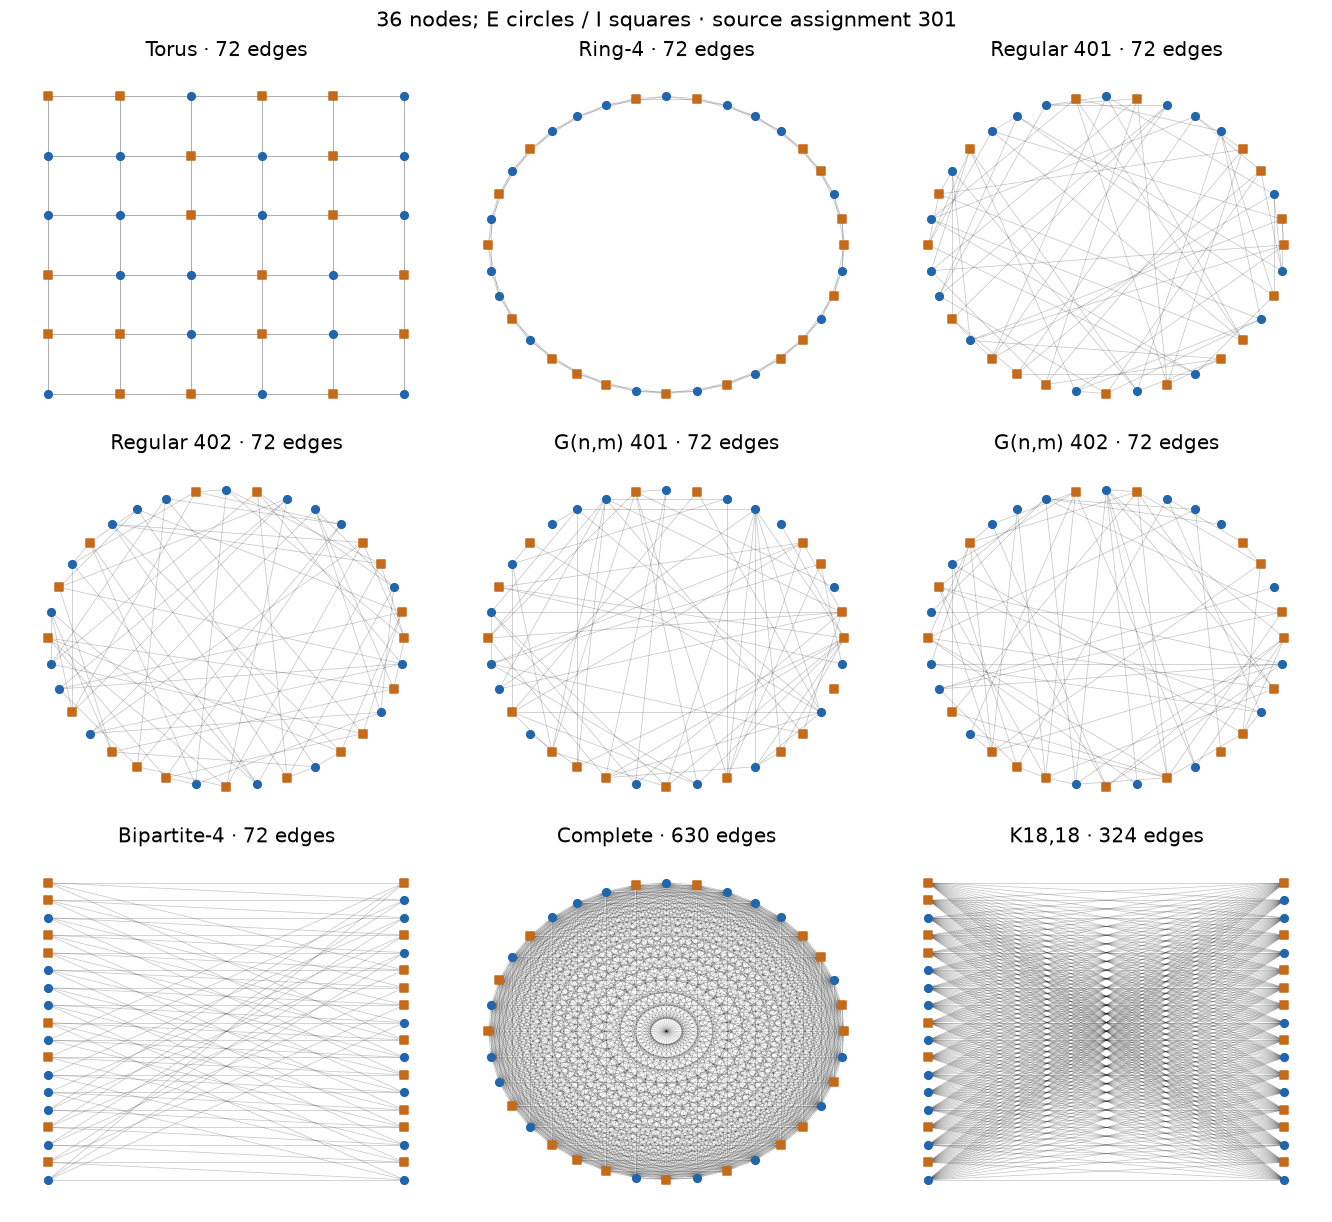

In [4]:
fig,axs=plt.subplots(3,3,figsize=(12,11),layout='constrained')
for ax,(name,g) in zip(axs.flat,GRAPHS.items()):
 if name=='torus':pos={i:(i%SIDE,-(i//SIDE)) for i in range(N)}
 elif name in BIPARTITE:pos={i:(0 if i<18 else 1,-(i%18)) for i in range(N)}
 else:pos=nx.circular_layout(list(range(N)))
 mask=LAYOUTS['random_301'];nx.draw_networkx_edges(g,pos,ax=ax,width=.5,alpha=.22)
 for flag,color,shape in [(True,BLUE,'o'),(False,ORANGE,'s')]:
  nx.draw_networkx_nodes(g,pos,nodelist=np.flatnonzero(mask==flag).tolist(),node_color=color,node_shape=shape,node_size=25,ax=ax)
 ax.set_title(f'{SHORT[name]} · {g.number_of_edges()} edges');ax.set_axis_off()
fig.suptitle('36 nodes; E circles / I squares · source assignment 301',fontsize=14)
save(fig,'01_graph_gallery')


## 2. Quantify structure and source exposure
Clustering is mean local triangle clustering; degree CV uses population standard deviation. Mean shortest path is reported only for connected graphs (otherwise NaN). The combinatorial Laplacian eigenvalue λ₂ is structural, not a stability test for these signed reversal-current dynamics. Source exposure is measured from G coefficients before gate activity or driving force.

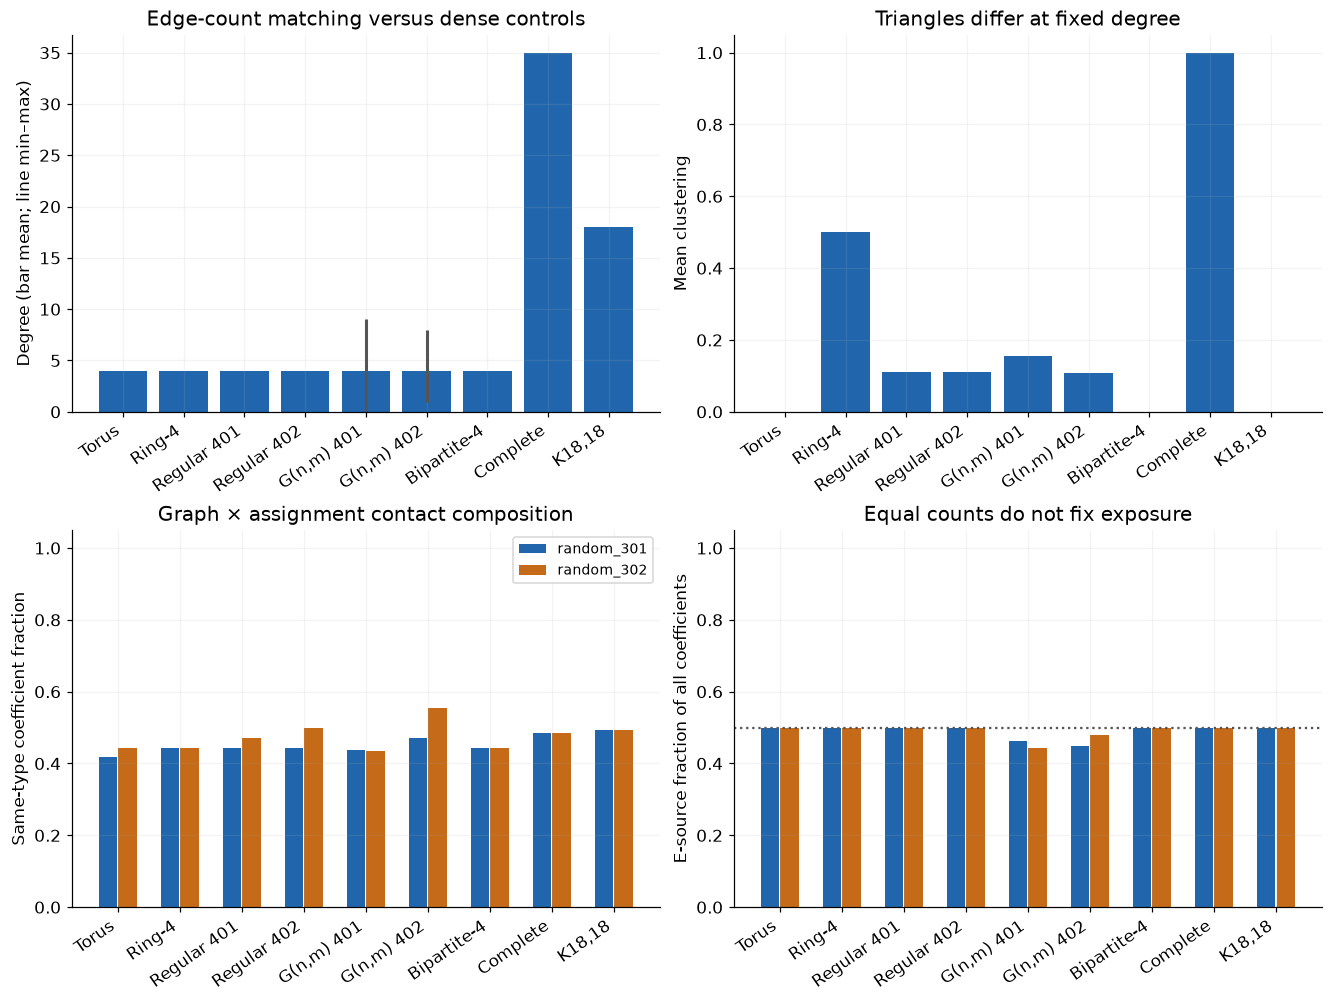

In [6]:
fig,axs=plt.subplots(2,2,figsize=(12,9),layout='constrained');xx=np.arange(len(NAMES));geo=geometry.set_index('graph').loc[NAMES]
axs[0,0].bar(xx,geo.mean_degree,color=BLUE);axs[0,0].vlines(xx,geo.min_degree,geo.max_degree,color=GRAY,lw=2)
axs[0,0].set(ylabel='Degree (bar mean; line min–max)',title='Edge-count matching versus dense controls')
axs[0,1].bar(xx,geo.clustering,color=BLUE);axs[0,1].set(ylabel='Mean clustering',ylim=(0,1.05),title='Triangles differ at fixed degree')
for layout,color,offset in [('random_301',BLUE,-.16),('random_302',ORANGE,.16)]:
 p=exposure[exposure.layout==layout].set_index('graph').loc[NAMES]
 axs[1,0].bar(xx+offset,p.same_type_fraction,width=.3,color=color,label=layout)
 axs[1,1].bar(xx+offset,p.E_source_coefficient_fraction,width=.3,color=color)
axs[1,0].set(ylabel='Same-type coefficient fraction',ylim=(0,1.05),title='Graph × assignment contact composition');axs[1,0].legend(fontsize=9)
axs[1,1].set(ylabel='E-source fraction of all coefficients',ylim=(0,1.05),title='Equal counts do not fix exposure');axs[1,1].axhline(.5,color=GRAY,linestyle=':')
for ax in axs.flat:ax.set_xticks(xx,LABELS,rotation=35,ha='right')
save(fig,'02_structure_and_source_exposure')

## 3. Reuse the continuous synaptic integrator
DOP853 uses rtol 10⁻¹⁰, atol 10⁻¹² and max step 0.25. An analytic sparse Jacobian supports independent Radau checks. Initial v,w are sampled from a settled isolated limit cycle with seeds 11/29; gates start at zero. The same node-labeled fields are reused across graph conditions.

In [8]:
def inputs(v,s,G,E):return G@(s*E)-v*(G@s)
def rhs_values(y,currents,G,E):
 v,w,s=y.reshape(-1,3).T
 return np.column_stack((v-v**3/3-w+currents+inputs(v,s,G,E),EPS*(v+A_REC-B_REC*w),
  ALPHA*expit(v/WIDTH)*(1-s)-BETA*s)).ravel()
def jacobian(y,G,E):
 n=len(E);v,w,s=y.reshape(n,3).T;q=expit(v/WIDTH);J=lil_matrix((3*n,3*n))
 degree=G@s
 for i in range(n):
  J[3*i,3*i]=1-v[i]**2-degree[i];J[3*i,3*i+1]=-1
  J[3*i+1,3*i]=EPS;J[3*i+1,3*i+1]=-EPS*B_REC
  J[3*i+2,3*i]=ALPHA*q[i]*(1-q[i])*(1-s[i])/WIDTH
  J[3*i+2,3*i+2]=-ALPHA*q[i]-BETA
  for j in G.getrow(i).indices:J[3*i,3*j+2]=G[i,j]*(E[j]-v[i])
 return J.tocsr()
def integrate(initial,G,E,end=END,method='DOP853',rtol=1e-10,atol=1e-12):
 initial=np.asarray(initial,float);G=np.asarray(G,float);E=np.asarray(E,float);n=len(E)
 if initial.shape!=(n,3) or G.shape!=(n,n):raise ValueError('Shape mismatch')
 if not np.isfinite(initial).all() or not np.isfinite(G).all() or not np.isfinite(E).all() or np.any(G<0) or np.any(np.diag(G)!=0):raise ValueError('Invalid state or conductance')
 if np.any(initial[:,2]<0) or np.any(initial[:,2]>1):raise ValueError('Initial gate outside [0,1]')
 Gs=csr_matrix(G);events=[]
 for i in range(n):
  def event(t,y,index=i):return y[3*index]
  event.direction=1;event.terminal=False;events.append(event)
 options={}
 if method in ['Radau','BDF']:options['jac']=lambda t,y:jacobian(y,Gs,E)
 sol=solve_ivp(lambda t,y:rhs_values(y,.5,Gs,E),(0,end),initial.ravel(),method=method,
  rtol=rtol,atol=atol,events=events,dense_output=True,max_step=.25,**options)
 if not sol.success:raise RuntimeError(sol.message)
 return sol
iso=integrate([[2.,-.5,0.]],np.zeros((1,1)),np.array([3.]),end=800.,rtol=1e-10,atol=1e-12)
t0,t1=iso.t_events[0][-2:];PERIOD=t1-t0
INITIAL={};init_rows=[]
for seed in PHASE_SEEDS:
 phases=np.random.default_rng(seed).uniform(0,1,N)
 states=iso.sol(t0+phases*PERIOD).reshape(3,N).T;states[:,2]=0;INITIAL[seed]=states
 for node,(q,z) in enumerate(zip(phases,states)):init_rows.append(dict(phase_seed=seed,node=node,phase_fraction=q,v=z[0],w=z[1],s=z[2]))
pd.DataFrame(init_rows).to_csv(OUT/'initial_states.csv',index=False)
print('Reference isolated period:',PERIOD)

Reference isolated period: 39.474414980238635


## 4. Measure dynamics in a fixed window
Run 9 graphs × 2 source assignments × 2 phase fields = **36 main conditions**, plus 2 bipartite graphs × 2 phase fields with partition-aligned E/I = **4 supplementary conditions**. Observe 400–1000 after the initial 400-unit transient; trajectories are not assumed equilibrated.

Event phase is linearly interpolated between positive v=0 crossings and never extrapolated. Global order $R=\langle|N^{-1}\sum_j e^{i\phi_j}|\rangle$ uses times supported by every node; coverage is saved. Missing support is NaN, not zero. Node count frequency is crossings divided by 600, so count resolution is 1/600 per node. The local uncancelled fraction is $C=\langle|J_E+J_I|\rangle/\langle|J_E|+|J_I|\rangle$ with absolute values taken before node/time averaging. It does not certify physiological balance. State spread centers v,w at each time. Arbitrary even/odd label metrics are omitted for abstract graphs.

In [10]:
def phase_order(phase,mask):
 if not np.any(mask):return np.nan,0.
 valid=np.isfinite(phase[mask]).all(axis=0)
 if not valid.any():return np.nan,0.
 return float(np.abs(np.mean(np.exp(1j*phase[mask][:,valid]),axis=0)).mean()),float(valid.mean())
def measure(sol,mask,G,start=BURN,stop=END):
 times=np.arange(start,stop+DT/10,DT);z=sol.sol(times).reshape(N,3,-1);v,w,s=z[:,0],z[:,1],z[:,2]
 G=csr_matrix(G);E=np.where(mask,3.,-3.)
 JE=inputs(v,s*mask[:,None],G,E[:,None]);JI=inputs(v,s*(~mask)[:,None],G,E[:,None])
 phase=np.full((N,len(times)),np.nan);node_rows=[]
 for i,e in enumerate(sol.t_events):
  recent=e[(e>=start)&(e<=stop)];isi=np.diff(recent)
  if len(e)>=2:
   valid=(times>=e[0])&(times<=e[-1]);phase[i,valid]=np.interp(times[valid],e,2*np.pi*np.arange(len(e)))
  node_rows.append(dict(node=i,source_type='E' if mask[i] else 'I',window_spikes=len(recent),count_frequency=len(recent)/(stop-start),
   period_frequency=float(1/isi.mean()) if len(isi)>=2 else np.nan,isi_cv=float(isi.std()/isi.mean()) if len(isi)>=2 else np.nan,
   mean_E_input=float(JE[i].mean()),mean_I_input=float(JI[i].mean()),rms_E_input=float(np.sqrt(np.mean(JE[i]**2))),rms_I_input=float(np.sqrt(np.mean(JI[i]**2)))))
 nodes=pd.DataFrame(node_rows);centered=z[:,:2]-z[:,:2].mean(axis=0,keepdims=True)
 total=float(np.mean(abs(JE)+abs(JI)));C=float(np.mean(abs(JE+JI))/total) if total>1e-15 else np.nan
 row=dict(state_spread=float(np.sqrt(np.mean(np.sum(centered**2,axis=1)))),mean_count_frequency=float(nodes.count_frequency.mean()),
  std_count_frequency=float(nodes.count_frequency.std(ddof=0)),nodes_with_spikes=int((nodes.window_spikes>0).sum()),
  mean_E_input=float(JE.mean()),mean_I_input=float(JI.mean()),local_uncancelled_fraction=C,
  E_count=int(mask.sum()),I_count=int((~mask).sum()))
 for name,pop in [('all',np.ones(N,dtype=bool)),('E',mask),('I',~mask)]:
  order,coverage=phase_order(phase,pop);row[f'phase_order_{name}']=order;row[f'phase_coverage_{name}']=coverage
  row[f'count_frequency_{name}']=float(nodes.loc[pop,'count_frequency'].mean()) if pop.any() else np.nan
 return row,nodes

rows=[];node_tables=[];event_rows=[];bounds=[];SELECTED={}
conditions=[(name,layout,seed,'main') for name in NAMES for layout in LAYOUTS for seed in PHASE_SEEDS]
conditions += [(name,'aligned',seed,'partition_control') for name in BIPARTITE for seed in PHASE_SEEDS]
for index,(name,layout,seed,role) in enumerate(conditions):
 mask=ALIGNED if layout=='aligned' else LAYOUTS[layout];G=G_MATRICES[name];E=np.where(mask,3.,-3.)
 sol=integrate(INITIAL[seed],G,E);stats,nodes=measure(sol,mask,G)
 run_id=f'run_{index+1:03d}';meta=dict(run_id=run_id,graph=name,layout=layout,phase_seed=seed,role=role)
 rows.append(dict(**meta,**stats));nodes['run_id']=run_id;node_tables.append(nodes)
 for i,e in enumerate(sol.t_events):event_rows.extend(dict(run_id=run_id,node=i,time=float(t)) for t in e)
 z=sol.sol(np.linspace(0,END,2001)).reshape(N,3,-1)
 bounds.append(dict(run_id=run_id,min_v=float(z[:,0].min()),max_v=float(z[:,0].max()),min_s=float(z[:,2].min()),max_s=float(z[:,2].max())))
 if seed==11 and ((layout=='random_301' and name in ['torus','ring4','regular401','complete_bipartite']) or (layout=='aligned' and name=='complete_bipartite')):SELECTED[(name,layout)]=sol
 _=(OUT/'progress.json').write_text(json.dumps(dict(status='running',completed=index+1,total=len(conditions))))
scan=pd.DataFrame(rows);scan.to_csv(OUT/'condition_metrics.csv',index=False)
pd.concat(node_tables,ignore_index=True).to_csv(OUT/'node_metrics.csv',index=False)
pd.DataFrame(event_rows).to_csv(OUT/'spike_events.csv',index=False)
bound_table=pd.DataFrame(bounds);bound_table.to_csv(OUT/'sampled_bounds.csv',index=False)
display(scan[(scan.layout=='random_301')&(scan.phase_seed==11)][['graph','mean_count_frequency','phase_order_all','phase_coverage_all','local_uncancelled_fraction']].round(5))


,graph,mean_count_frequency,phase_order_all,phase_coverage_all,local_uncancelled_fraction
0,torus,0.02620,0.27972,0.93589,0.50522
4,ring4,0.02611,0.21863,0.93256,0.45919
8,regular401,0.02565,0.24014,0.93505,0.49399
12,regular402,0.02616,0.34863,0.93589,0.53173
16,gnm401,0.02630,0.31918,0.94172,0.50882
20,gnm402,0.02597,0.35649,0.93755,0.54385
24,bipartite4,0.02606,0.27494,0.93672,0.46966
28,complete,0.02634,0.96329,0.96170,0.41713
32,complete_bipartite,0.02588,0.90594,0.96003,0.39532


## 5. Compare all paired conditions
Each marker is an individual deterministic condition, not a confidence interval. Blue/orange denote the two fixed source assignments; circles/squares denote the two phase fields. Dense controls change degree and individual contact strength. The 4-regular subset (torus, ring, two regular draws and bipartite-4) also matches degree, edge count and edge strength; source exposure/composition and other graph features can still differ.

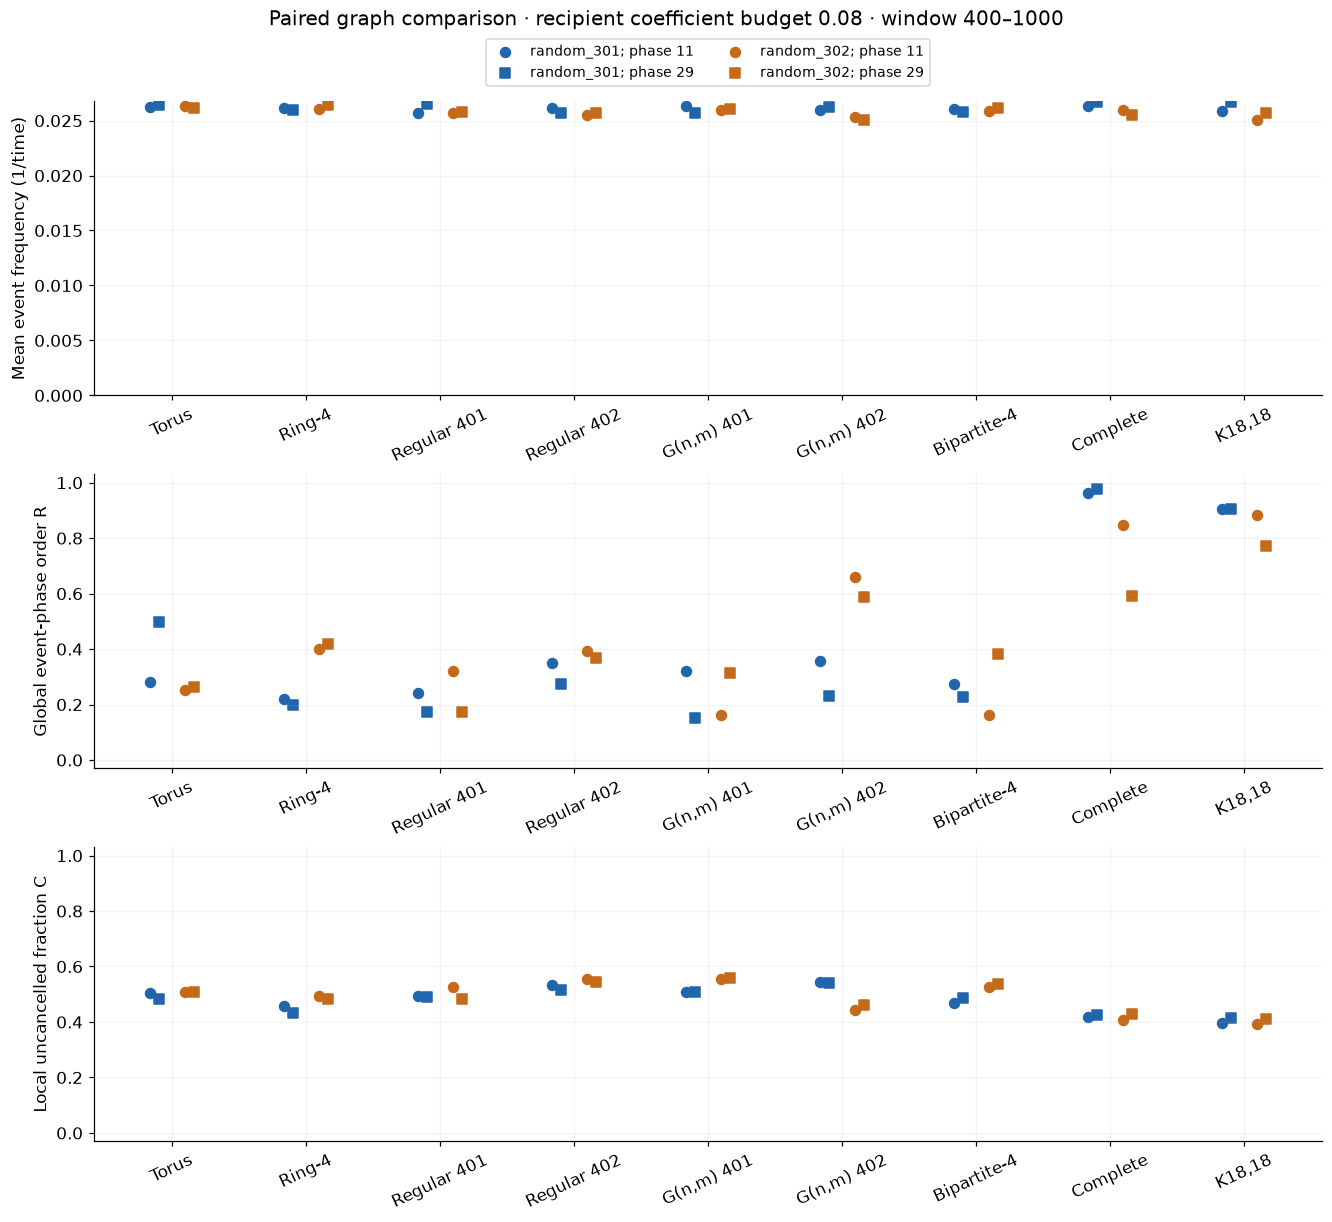

In [12]:
fig,axs=plt.subplots(3,1,figsize=(12,11),layout='constrained');xx=np.arange(len(NAMES))
metrics=[('mean_count_frequency','Mean event frequency (1/time)'),('phase_order_all','Global event-phase order R'),('local_uncancelled_fraction','Local uncancelled fraction C')]
for ax,(metric,label) in zip(axs,metrics):
 for layout,color,offset in [('random_301',BLUE,-.13),('random_302',ORANGE,.13)]:
  for seed,marker,shift in [(11,'o',-.035),(29,'s',.035)]:
   p=scan[(scan.layout==layout)&(scan.phase_seed==seed)].set_index('graph').loc[NAMES]
   ax.scatter(xx+offset+shift,p[metric],color=color,marker=marker,s=42,label=f'{layout}; phase {seed}')
 ax.set(ylabel=label,xticks=xx,xticklabels=LABELS);ax.tick_params(axis='x',rotation=25)
 if metric!='mean_count_frequency':ax.set_ylim(-.03,1.03)
 else:ax.set_ylim(bottom=0)
axs[0].legend(loc='lower center',bbox_to_anchor=(.5,1.03),ncol=2,fontsize=9)
fig.suptitle('Paired graph comparison · recipient coefficient budget 0.08 · window 400–1000',fontsize=13)
save(fig,'03_paired_dynamical_comparison')

## 6. Distinguish bipartition from source identity
Both bipartite graphs use partitions {0,…,17} and {18,…,35}. The aligned control sets the first partition E and second I. Then every recipient receives only one source type and C=1 whenever input is nonzero, even though the network contains equal numbers of E and I neurons. Random assignments generally mix source types within both partitions. These controls test assignment–topology interaction; they are not extra random-assignment replicates.

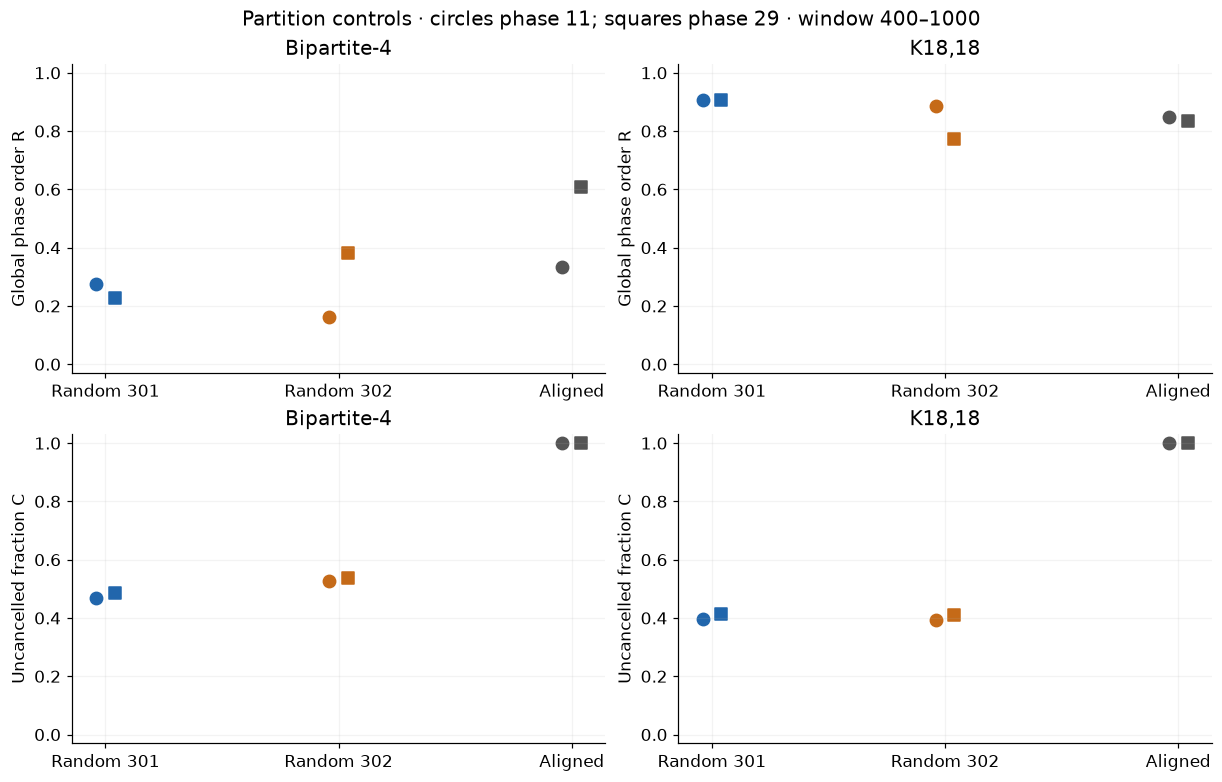

In [14]:
fig,axs=plt.subplots(2,2,figsize=(11,7),layout='constrained')
layouts=['random_301','random_302','aligned'];colors=[BLUE,ORANGE,GRAY]
for col,name in enumerate(BIPARTITE):
 for row,(metric,label) in enumerate([('phase_order_all','Global phase order R'),('local_uncancelled_fraction','Uncancelled fraction C')]):
  ax=axs[row,col]
  for x,(layout,color) in enumerate(zip(layouts,colors)):
   for seed,marker,shift in [(11,'o',-.04),(29,'s',.04)]:
    val=scan[(scan.graph==name)&(scan.layout==layout)&(scan.phase_seed==seed)][metric].iloc[0]
    ax.scatter(x+shift,val,color=color,marker=marker,s=65)
  ax.set(xticks=range(3),xticklabels=['Random 301','Random 302','Aligned'],ylabel=label,title=SHORT[name],ylim=(-.03,1.03))
fig.suptitle('Partition controls · circles phase 11; squares phase 29 · window 400–1000')
save(fig,'04_partition_alignment_controls')

## 7. Inspect node-resolved event timing
Show four selected graph/assignment conditions at phase seed 11 over 800–1000. Raster rank groups E first, then I; it is not the original node index or a physical coordinate. All plotted events are saved in `spike_events.csv`.

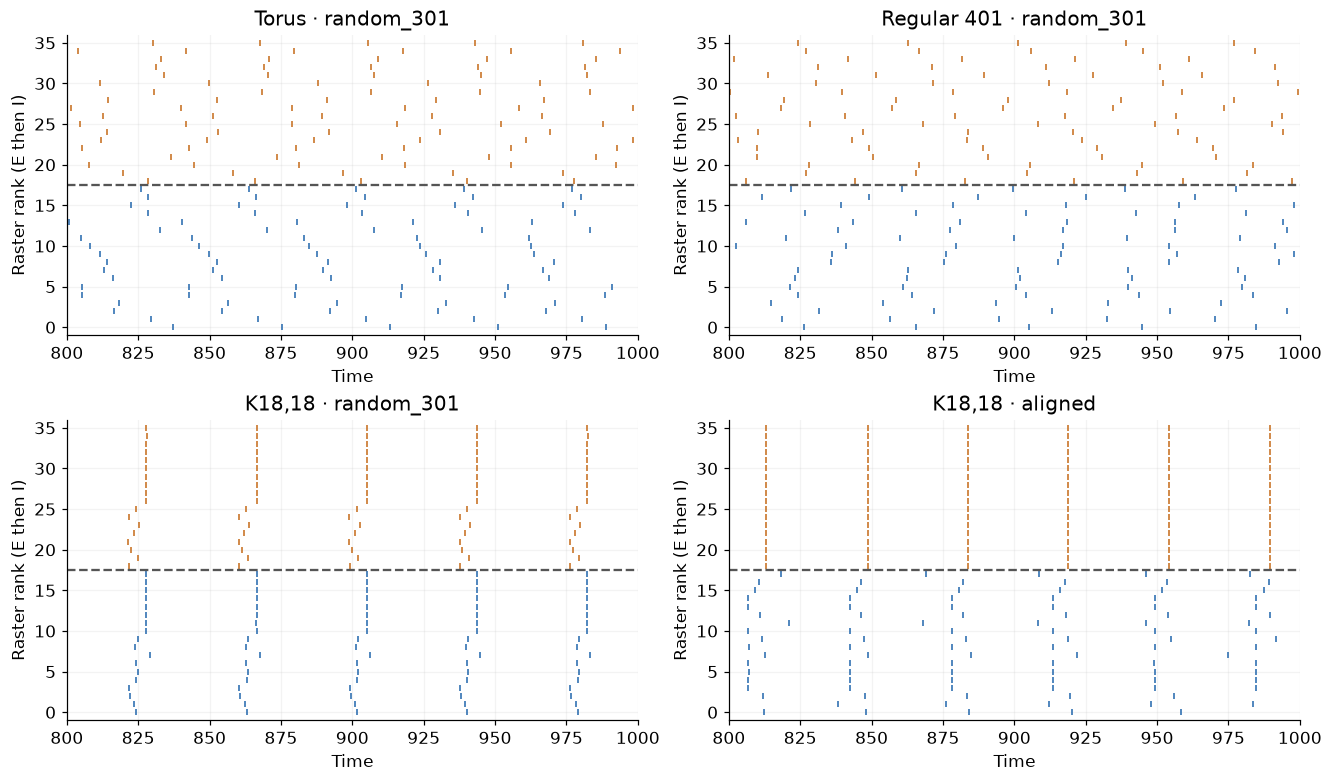

In [16]:
fig,axs=plt.subplots(2,2,figsize=(12,7),layout='constrained')
RASTER_KEYS=[('torus','random_301'),('regular401','random_301'),('complete_bipartite','random_301'),('complete_bipartite','aligned')]
for ax,key in zip(axs.flat,RASTER_KEYS):
 name,layout=key;mask=ALIGNED if layout=='aligned' else LAYOUTS[layout];sol=SELECTED[key];order=np.r_[np.flatnonzero(mask),np.flatnonzero(~mask)]
 for rank,node in enumerate(order):
  events=sol.t_events[node];events=events[(events>=800)&(events<=1000)]
  ax.plot(events,np.full(len(events),rank),'|',color=BLUE if mask[node] else ORANGE,markersize=4)
 ax.axhline(17.5,color=GRAY,linestyle='--');ax.set(xlim=(800,1000),ylim=(-1,N),xlabel='Time',ylabel='Raster rank (E then I)',title=f'{SHORT[name]} · {layout}')
save(fig,'05_selected_rasters')

## 8. Validate structural contracts and numerical accuracy
Check graph size, simple undirected support, degree/edge controls, recipient budgets, source counts and numerical gate/current signs. Relabel a whole graph, state and source mask together to test equivariance. Compare independent Radau over 0–200 and tighter DOP853 over 0–1000 for one irregular G(n,m) trajectory. These selected checks are not an accuracy certificate for all trajectories. Extend three selected conditions to 2000 to compare windows 400–1000 and 1400–2000. The early audit uses the same 1000-unit trajectory and event support as the main comparison; only the later window uses the extended trajectory. Thus future events from an extension do not alter the early-window phase coverage.

,check,error,limit,passed
53,Sampled v inside reversals,0.000000e+00,1.000000e-08,True
54,E current nonnegative,0.000000e+00,1.000000e-10,True
55,I current nonpositive,0.000000e+00,1.000000e-10,True
56,Aligned bipartite has C=1,0.000000e+00,1.000000e-10,True
57,Isolated recipient normalization,0.000000e+00,1.000000e-12,True
58,Joint node-relabel equivariance of RHS,0.000000e+00,1.000000e-12,True
59,Independent solver states 0–200,4.241887e-09,2.000000e-04,True
60,Independent event times 0–200,1.196625e-09,2.000000e-04,True
61,Tighter states 0–1000,3.578448e-08,2.000000e-03,True
62,Tighter event times 0–1000,2.336481e-08,2.000000e-03,True


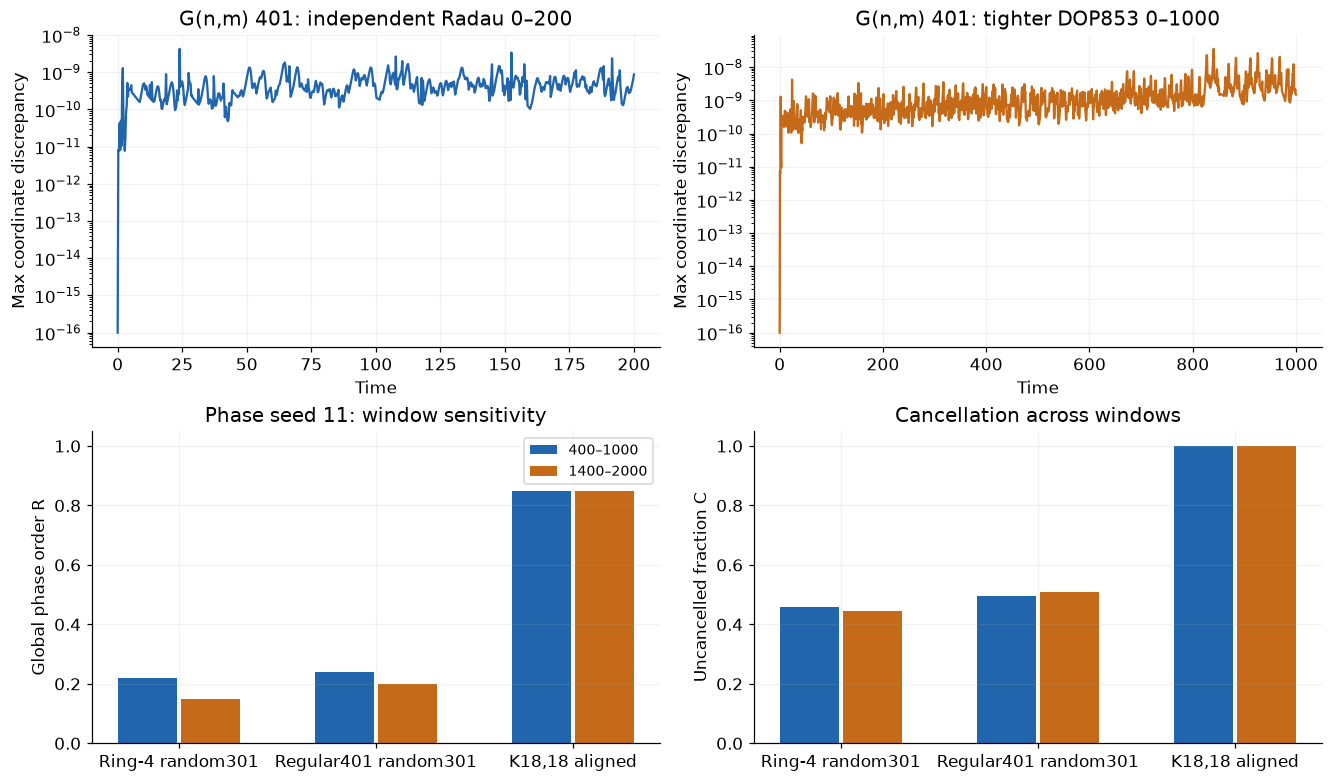

40 conditions; 63 checks passed.


In [19]:
checks=[]
def check(name,error,limit):checks.append(dict(check=name,error=float(error),limit=float(limit),passed=bool(error<limit)))
for name,A in ADJ.items():
 G=G_MATRICES[name];degree=A.sum(axis=1)
 check(name+': node count',abs(A.shape[0]-36),.5)
 check(name+': simple undirected',abs(A-A.T).max()+abs(np.diag(A)).max()+np.max(np.minimum(abs(A),abs(A-1))),1e-12)
 check(name+': recipient budget',abs(G.sum(axis=1)-np.where(degree>0,.08,0)).max(),1e-12)
 check(name+': support preserved',np.max(abs(G[A==0])) if np.any(A==0) else 0,1e-12)
for name in ['torus','ring4','regular401','regular402','bipartite4']:
 check(name+': degree four',abs(ADJ[name].sum(axis=1)-4).max(),1e-12)
 check(name+': edge coefficient .02',abs(G_MATRICES[name][ADJ[name]>0]-.02).max(),1e-12)
for name in ['gnm401','gnm402']:check(name+': 72 edges',abs(GRAPHS[name].number_of_edges()-72),.5)
for layout,mask in {**LAYOUTS,'aligned':ALIGNED}.items():check(layout+': 18 E sources',abs(mask.sum()-18),.5)
check('40 conditions',abs(len(scan)-40),.5)
check('Sampled gates in [0,1]',max(0.,-bound_table.min_s.min(),bound_table.max_s.max()-1),1e-8)
check('Sampled v inside reversals',max(0.,-3-bound_table.min_v.min(),bound_table.max_v.max()-3),1e-8)
check('E current nonnegative',max(0.,-scan.mean_E_input.min()),1e-10)
check('I current nonpositive',max(0.,scan.mean_I_input.max()),1e-10)
check('Aligned bipartite has C=1',abs(scan[scan.layout=='aligned'].local_uncancelled_fraction-1).max(),1e-10)
Z=np.zeros((N,N));check('Isolated recipient normalization',abs(normalize(Z)).max(),1e-12)
name='gnm401';G=G_MATRICES[name];mask=LAYOUTS['random_301'];E=np.where(mask,3.,-3.);initial=INITIAL[11]
perm=np.random.default_rng(91).permutation(N)
f=rhs_values(initial.ravel(),.5,csr_matrix(G),E).reshape(N,3)
fp=rhs_values(initial[perm].ravel(),.5,csr_matrix(G[np.ix_(perm,perm)]),E[perm]).reshape(N,3)
check('Joint node-relabel equivariance of RHS',abs(fp-f[perm]).max(),1e-12)
base=integrate(initial,G,E);ref=integrate(initial,G,E,end=200.,method='Radau',rtol=2e-11,atol=2e-13)
tshort=np.linspace(0,200,801);independent_error=float(abs(base.sol(tshort)-ref.sol(tshort)).max());check('Independent solver states 0–200',independent_error,2e-4)
independent_events=0.
for e,er in zip(base.t_events,ref.t_events):
 e=e[e<=200];assert len(e)==len(er)
 if len(e):independent_events=max(independent_events,float(abs(e-er).max()))
check('Independent event times 0–200',independent_events,2e-4)
tight=integrate(initial,G,E,rtol=1e-12,atol=1e-14);tfull=np.linspace(0,END,2001)
tight_error=float(abs(base.sol(tfull)-tight.sol(tfull)).max());check('Tighter states 0–1000',tight_error,2e-3)
tight_events=0.
for e,er in zip(base.t_events,tight.t_events):
 assert len(e)==len(er)
 if len(e):tight_events=max(tight_events,float(abs(e-er).max()))
check('Tighter event times 0–1000',tight_events,2e-3)
validation=pd.DataFrame(checks);validation.to_csv(OUT/'validation_checks.csv',index=False)
display(validation.tail(10));assert validation.passed.all()
window_rows=[]
WINDOW_KEYS=[('ring4','random_301'),('regular401','random_301'),('complete_bipartite','aligned')]
for name,layout in WINDOW_KEYS:
 mask=ALIGNED if layout=='aligned' else LAYOUTS[layout];G=G_MATRICES[name];E=np.where(mask,3.,-3.)
 long=integrate(INITIAL[11],G,E,end=2000.)
 for start,stop in [(400.,1000.),(1400.,2000.)]:
  stats,_=measure(SELECTED[(name,layout)] if stop==END else long,mask,G,start,stop);window_rows.append(dict(graph=name,layout=layout,window=f'{int(start)}–{int(stop)}',**stats))
windows=pd.DataFrame(window_rows);windows.to_csv(OUT/'window_sensitivity.csv',index=False)
fig,axs=plt.subplots(2,2,figsize=(12,7),layout='constrained')
axs[0,0].semilogy(tshort,np.maximum(np.max(abs(base.sol(tshort)-ref.sol(tshort)),axis=0),1e-16),color=BLUE)
axs[0,0].set(xlabel='Time',ylabel='Max coordinate discrepancy',title='G(n,m) 401: independent Radau 0–200')
axs[0,1].semilogy(tfull,np.maximum(np.max(abs(base.sol(tfull)-tight.sol(tfull)),axis=0),1e-16),color=ORANGE)
axs[0,1].set(xlabel='Time',ylabel='Max coordinate discrepancy',title='G(n,m) 401: tighter DOP853 0–1000')
xx=np.arange(len(WINDOW_KEYS))
for window,color,offset in [('400–1000',BLUE,-.16),('1400–2000',ORANGE,.16)]:
 p=windows[windows.window==window].set_index(['graph','layout']).loc[WINDOW_KEYS]
 axs[1,0].bar(xx+offset,p.phase_order_all,width=.3,color=color,label=window)
 axs[1,1].bar(xx+offset,p.local_uncancelled_fraction,width=.3,color=color)
for ax in axs[1,:]:ax.set(xticks=xx,xticklabels=['Ring-4 random301','Regular401 random301','K18,18 aligned'],ylim=(0,1.05))
axs[1,0].set(ylabel='Global phase order R',title='Phase seed 11: window sensitivity');axs[1,0].legend(fontsize=9)
axs[1,1].set(ylabel='Uncancelled fraction C',title='Cancellation across windows')
save(fig,'06_accuracy_and_window_sensitivity')
summary=dict(versions=versions,nodes=N,graphs=NAMES,source_assignments=list(LAYOUTS),phase_seeds=PHASE_SEEDS,
 main_conditions=36,partition_controls=4,conditions=len(scan),duration=END,burn=BURN,sampling_step=DT,recipient_budget=ROW_BUDGET,
 graph_seeds=[401,402],source_seeds=[301,302],solver=dict(method='DOP853',rtol=1e-10,atol=1e-12,max_step=.25),
 parameters=dict(a=A_REC,b=B_REC,epsilon=EPS,current=.5,alpha=ALPHA,beta=BETA,width=WIDTH,E_E=3.,E_I=-3.),
 checks_passed=int(validation.passed.sum()),independent_horizon=200.,independent_state_error=independent_error,
 independent_event_error=independent_events,tighter_full_state_error=tight_error,tighter_full_event_error=tight_events)
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
_=(OUT/'progress.json').write_text(json.dumps(dict(status='complete',completed=len(scan),total=len(scan))))
print(len(scan),'conditions;',len(checks),'checks passed.')

## 9. Resolve the disconnected draw by component
G(n,m) seed 401 has components of size 35 and 1. Keep the isolated node in the experiment and compare global phase order with the 35-node component. A singleton has phase order 1 by definition whenever its phase is supported; that number is not evidence of collective coherence, so its event frequency is shown instead. Component tables are provided for every condition; node counts and weighted mean frequencies must reconcile with the global results.

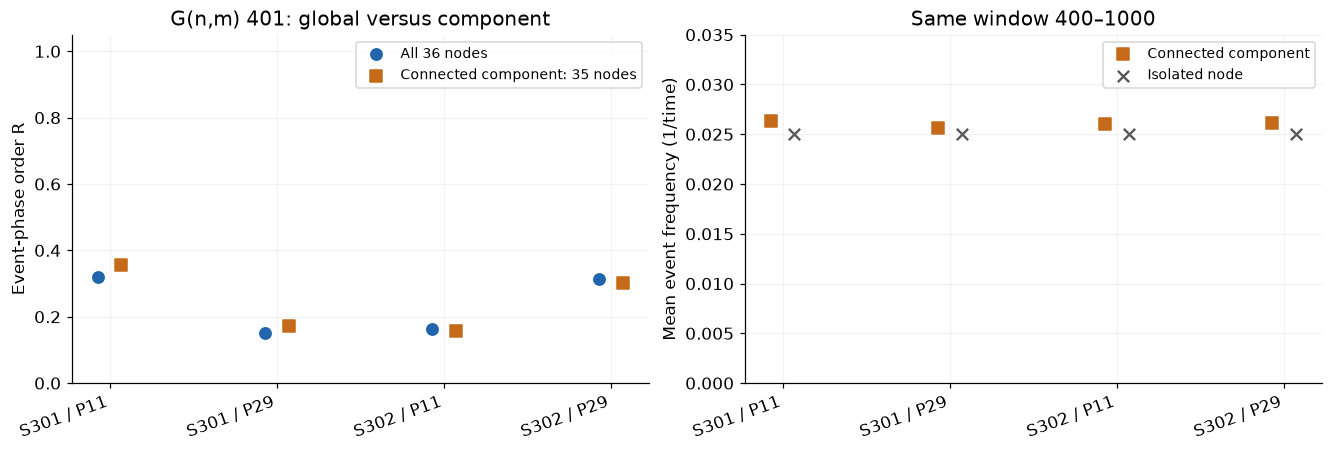

,layout,phase_seed,node_count,phase_order,phase_coverage,mean_count_frequency
16,random_301,11,35,0.35504,0.94172,0.02633
17,random_301,11,1,1.00000,0.94921,0.02500
18,random_301,29,35,0.17251,0.93672,0.02567
19,random_301,29,1,1.00000,0.94088,0.02500
20,random_302,11,35,0.15753,0.93256,0.02600
21,random_302,11,1,1.00000,0.94921,0.02500
22,random_302,29,35,0.30259,0.93672,0.02610
23,random_302,29,1,1.00000,0.94088,0.02500


67 checks passed including component reconciliation.


In [20]:
events=pd.read_csv(OUT/'spike_events.csv');component_rows=[];times=np.arange(BURN,END+DT/10,DT)
for _,run in scan.iterrows():
 g=GRAPHS[run['graph']];ev=events[events.run_id==run.run_id];phase=np.full((N,len(times)),np.nan)
 for node,part in ev.groupby('node'):
  ee=part.time.to_numpy()
  if len(ee)>=2:
   valid=(times>=ee[0])&(times<=ee[-1]);phase[int(node),valid]=np.interp(times[valid],ee,2*np.pi*np.arange(len(ee)))
 for component,nodeset in enumerate(sorted(nx.connected_components(g),key=lambda x:(-len(x),min(x)))):
  mask=np.zeros(N,dtype=bool);mask[list(nodeset)]=True;order,coverage=phase_order(phase,mask)
  selected=ev[ev.node.isin(nodeset)&(ev.time>=BURN)&(ev.time<=END)]
  component_rows.append(dict(run_id=run.run_id,graph=run['graph'],layout=run.layout,phase_seed=run.phase_seed,
   component=component,node_count=len(nodeset),nodes=' '.join(map(str,sorted(nodeset))),phase_order=order,phase_coverage=coverage,
   mean_count_frequency=len(selected)/(len(nodeset)*(END-BURN))))
components=pd.DataFrame(component_rows);components.to_csv(OUT/'component_metrics.csv',index=False)
p=scan[scan.graph=='gnm401'].copy();p['condition']=p.layout.str.replace('random_','S',regex=False)+' / P'+p.phase_seed.astype(str)
fig,axs=plt.subplots(1,2,figsize=(12,4),layout='constrained');xx=np.arange(len(p))
large=components[(components.graph=='gnm401')&(components.node_count>1)].set_index('run_id').loc[p.run_id]
isolated=components[(components.graph=='gnm401')&(components.node_count==1)].set_index('run_id').loc[p.run_id]
axs[0].scatter(xx-.07,p.phase_order_all,color=BLUE,marker='o',s=55,label='All 36 nodes')
axs[0].scatter(xx+.07,large.phase_order,color=ORANGE,marker='s',s=55,label='Connected component: 35 nodes')
axs[0].set(ylabel='Event-phase order R',ylim=(0,1.05),title='G(n,m) 401: global versus component');axs[0].legend(fontsize=9)
axs[1].scatter(xx-.07,large.mean_count_frequency,color=ORANGE,marker='s',s=55,label='Connected component')
axs[1].scatter(xx+.07,isolated.mean_count_frequency,color=GRAY,marker='x',s=55,label='Isolated node')
axs[1].set(ylabel='Mean event frequency (1/time)',ylim=(0,.035),title='Same window 400–1000');axs[1].legend(fontsize=9)
for ax in axs:ax.set_xticks(xx,p.condition,rotation=20,ha='right')
save(fig,'07_disconnected_component_diagnostic')
display(components[(components.graph=='gnm401')][['layout','phase_seed','node_count','phase_order','phase_coverage','mean_count_frequency']].round(5))
check('Components partition all nodes',abs(components.groupby('run_id').node_count.sum()-N).max(),.5)
weighted=components.assign(weighted_frequency=components.node_count*components.mean_count_frequency).groupby('run_id').weighted_frequency.sum()/N
check('Component frequencies reconcile globally',abs(weighted-scan.set_index('run_id').mean_count_frequency).max(),1e-12)
check('G(n,m)401 component sizes 35 and 1',abs(np.sort([len(c) for c in nx.connected_components(GRAPHS['gnm401'])])-np.array([1,35])).max(),.5)
connected=components[components.node_count==N].set_index('run_id')
check('Connected-component phase matches global',abs(connected.phase_order-scan.set_index('run_id').loc[connected.index,'phase_order_all']).max(),1e-12)
validation=pd.DataFrame(checks);validation.to_csv(OUT/'validation_checks.csv',index=False);assert validation.passed.all()
summary=json.loads((OUT/'summary.json').read_text());summary.update(checks_passed=int(validation.passed.sum()),figures=7,component_diagnostic=True)
_=(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print(len(checks),'checks passed including component reconciliation.')


## Limits and next graph experiments
This notebook compares explicit finite graph realizations. It does not isolate one scalar topology statistic as a cause of activity, estimate a graph-ensemble effect, prove synchronization stability, or establish asymptotic attractors. Paired assignments and phases improve comparability but are not independent observations for confidence intervals. Disconnected graphs, if realized, are retained and their component count/isolation reported; global phase order can hide independent component behavior. Mean path length is missing for disconnected graphs rather than replaced by an undocumented convention.

Regular comparisons hold degree and per-edge weights fixed, but clustering, path structure, E/I contact composition and other features co-vary. Dense controls retain the recipient budget but alter individual edge weights and source averaging. No universal sparse/dense or graph-family ranking follows. Different initial phases and finite windows can change observations; numeric solver checks address selected trajectories only. A display floor of 10⁻¹⁶ is used in discrepancy plots.

Next: degree-preserving rewiring with more graph/assignment/phase replicates; then controlled degree and size sweeps, component and size controls and shortest-path-based kernels. Graph shortest-path distance would be a new coupling choice, not the spatial Euclidean distance of notebook 15. Mixed neuronal model types at nodes remain a later extension.

References: [NetworkX fixed-edge G(n,m)](https://networkx.org/documentation/stable/reference/generated/networkx.generators.random_graphs.gnm_random_graph.html), [random regular graph generator](https://networkx.org/documentation/stable/reference/generated/networkx.generators.random_graphs.random_regular_graph.html), [Neuronal Dynamics: reversal currents and gates](https://neuronaldynamics.epfl.ch/online/Ch3.S1.html), [SciPy integration and events](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html). The equations/parameters, chosen graph controls, initial fields and metrics are explicitly specified here; these references do not establish biological calibration or a graph-dynamics prediction.